In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from apyori import apriori


In [14]:
df = pd.read_csv("Market_Basket_Optimisation.csv", header=None)

transactions = []

for i in range(len(df)):
    row = df.iloc[i].dropna().tolist()
    transactions.append(row)

print("Total transactions:", len(transactions))
print(transactions[:2])

Total transactions: 7501
[['shrimp', 'almonds', 'avocado', 'vegetables mix', 'green grapes', 'whole weat flour', 'yams', 'cottage cheese', 'energy drink', 'tomato juice', 'low fat yogurt', 'green tea', 'honey', 'salad', 'mineral water', 'salmon', 'antioxydant juice', 'frozen smoothie', 'spinach', 'olive oil'], ['burgers', 'meatballs', 'eggs']]


In [4]:

results = list(apriori(transactions,
                      min_support=0.003,
                      min_confidence=0.2,
                      min_lift=3,
                      min_length=2))


In [9]:
rules = []

for r in results:
    for o in r.ordered_statistics:
        if o.items_base:
            rules.append([
                list(o.items_base),
                list(o.items_add),
                r.support,
                o.confidence,
                o.lift
            ])

rules = pd.DataFrame(rules, columns=["If", "Then", "Support", "Confidence", "Lift"])

print(rules.head(10))


                       If           Then   Support  Confidence      Lift
0           [light cream]      [chicken]  0.004533    0.290598  4.843951
1  [mushroom cream sauce]     [escalope]  0.005733    0.300699  3.790833
2                 [pasta]     [escalope]  0.005866    0.372881  4.700812
3         [fromage blanc]        [honey]  0.003333    0.245098  5.164271
4         [herb & pepper]  [ground beef]  0.015998    0.323450  3.291994
5          [tomato sauce]  [ground beef]  0.005333    0.377358  3.840659
6           [light cream]    [olive oil]  0.003200    0.205128  3.114710
7     [whole wheat pasta]    [olive oil]  0.007999    0.271493  4.122410
8                 [pasta]       [shrimp]  0.005066    0.322034  4.506672
9    [spaghetti, avocado]         [milk]  0.003333    0.416667  3.215449


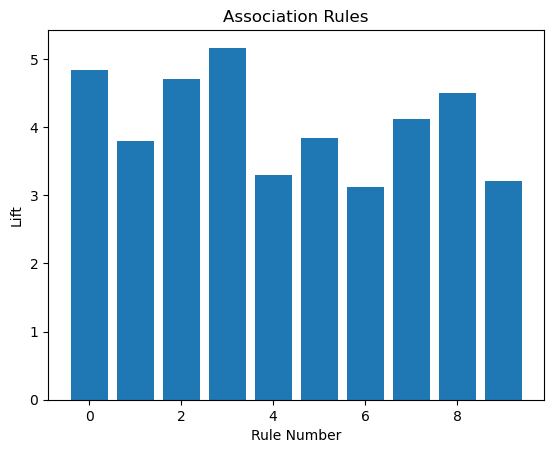

In [12]:

top = rules.head(10)

plt.bar(range(len(top)), top["Lift"])
plt.xlabel("Rule Number")
plt.ylabel("Lift")
plt.title("Association Rules")
plt.show()
